# Clasificación de 3 escenas con Vision Transformer (ViT)

Implementación de un **ViT** (*Vision Transformer*, Dosovitskiy et al., 2021)
en Keras, entrenado **desde cero** sobre el dataset local de 3 escenas
(`coast`, `forest`, `highway`; 958 imágenes). El enunciado pide «un modelo
Transformer para hacer la clasificación (puede ser ViT, SWIN u otro)»: este
cuaderno cubre la bala de IA generativa del reto con el ViT, que se suma a las
dos CNN y a la DenseNet121 preentrenada de la comparación.

**Cómo funciona el ViT.** Trocea la imagen en parches y aplica atención
**global**: cada token atiende a todos los demás en todas las capas, así que el
coste crece con el cuadrado del número de tokens, `O(n²)`. La arquitectura es
**plana**: una única secuencia de tokens (16×16 = 256 parches de 8×8 sobre la
entrada de 128×128, más el token de clase) atraviesa seis bloques idénticos sin
reducir la resolución espacial ni duplicar la dimensión, así que el modelo
clasifica apoyándose solo en el token de clase.

Este ViT se entrena **desde cero** (sin pesos de ImageNet) con el split
congelado común del reto (≈ 610 train / 108 validación / 240 test, semilla 20,
`resultados/split.json`): la comparación con la CNN mejorada v2, que también
arranca desde cero, aísla la arquitectura, y la comparación con la DenseNet121
(ImageNet) suma el efecto del preentrenamiento.

El modelo se carga desde `resultados/vit/` por defecto (las capas
personalizadas no se deserializan con fiabilidad, así que se reconstruye la
arquitectura con `build_vit()` y se cargan los pesos de `model.weights.h5`).
Cambia `FORCE_RETRAIN = True` para entrenarlo de nuevo.


In [1]:
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from keras import layers, ops
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.losses import CategoricalCrossentropy
from keras.optimizers import AdamW

import common_3scenes as cs

FORCE_RETRAIN = False
sns.set_theme(style="whitegrid", context="notebook")
keras.utils.set_random_seed(cs.SEED)
np.random.seed(cs.SEED)

data = cs.load_split_data()
X_train = data["X_train"].astype("float32")
X_val = data["X_val"].astype("float32")
X_test = data["X_test"].astype("float32")
y_train_labels = data["y_train"]
y_val_labels = data["y_val"]
y_test_labels = data["y_test"]
test_paths = data["test_paths"]

y_train = cs.one_hot(y_train_labels)
y_val = cs.one_hot(y_val_labels)

print("Train:", X_train.shape, "| Validación:", X_val.shape, "| Test:", X_test.shape)
print("Distribución de test:", {name: int(np.sum(y_test_labels == name)) for name in cs.CLASSES})

I0000 00:00:1795047735.970856  103296 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795047736.135086  103296 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795047737.343715  103296 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Train: (610, 128, 128, 3) | Validación: (108, 128, 128, 3) | Test: (240, 128, 128, 3)
Distribución de test: {'coast': 90, 'forest': 82, 'highway': 68}


In [2]:
# ViT hyperparameters: 8x8 patches over the 128x128 input -> 16x16 = 256 patches.
PATCH = 8
EMBED_DIM = 256
DEPTH = 6
NUM_HEADS = 8
MLP_DIM = 1024  # EMBED_DIM * 4, the standard transformer MLP expansion
DROP_RATE = 0.1
INPUT_SIZE = 128


class PatchEmbedding(layers.Layer):
    """Turn the image into a flat sequence of patch embeddings.

    A ``Conv2D`` with kernel and stride equal to the patch size produces one
    token per patch, reshaped to ``(batch, num_patches, embed_dim)``.
    """

    def __init__(self, embed_dim, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.proj = layers.Conv2D(
            filters=embed_dim,
            kernel_size=patch_size,
            strides=patch_size,
            padding="valid",
        )

    def call(self, x):
        x = self.proj(x)
        _, height, width, channels = x.shape
        return ops.reshape(x, (-1, height * width, channels))


class PatchEncoder(layers.Layer):
    """Prepend a learnable class token and add learnable position embeddings."""

    def __init__(self, num_patches, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.class_token = self.add_weight(
            shape=(1, 1, embed_dim),
            initializer=keras.initializers.TruncatedNormal(stddev=0.02),
            trainable=True,
            name="class_token",
        )
        self.position_embedding = self.add_weight(
            shape=(1, num_patches + 1, embed_dim),
            initializer=keras.initializers.TruncatedNormal(stddev=0.02),
            trainable=True,
            name="position_embedding",
        )

    def call(self, x):
        batch_size = ops.shape(x)[0]
        class_token = ops.broadcast_to(
            self.class_token, (batch_size, 1, x.shape[-1])
        )
        x = ops.concatenate([class_token, x], axis=1)
        return x + self.position_embedding


class TransformerBlock(layers.Layer):
    """Pre-norm block: MHSA with residual, then MLP with residual."""

    def __init__(self, embed_dim, num_heads, mlp_dim, drop_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.attn = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=drop_rate,
        )
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.mlp = keras.Sequential(
            [
                layers.Dense(mlp_dim),
                layers.Activation("gelu"),
                layers.Dropout(drop_rate),
                layers.Dense(embed_dim),
                layers.Dropout(drop_rate),
            ]
        )
        self.drop = layers.Dropout(drop_rate)

    def call(self, x, training=False):
        shortcut = x
        x = self.norm1(x)
        x = self.attn(x, x, training=training)
        x = shortcut + self.drop(x, training=training)
        return x + self.drop(self.mlp(self.norm2(x), training=training), training=training)


def build_vit(
    input_size=INPUT_SIZE,
    patch_size=PATCH,
    embed_dim=EMBED_DIM,
    depth=DEPTH,
    num_heads=NUM_HEADS,
    mlp_dim=MLP_DIM,
    drop_rate=DROP_RATE,
    num_classes=len(cs.CLASSES),
):
    """Build and compile the flat ViT for the 3-scene dataset."""
    inputs = layers.Input(shape=(input_size, input_size, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.05)(x)
    x = layers.Rescaling(1.0 / 255.0)(x)
    num_patches = (input_size // patch_size) ** 2
    x = PatchEmbedding(embed_dim, patch_size)(x)
    x = PatchEncoder(num_patches, embed_dim)(x)
    for _ in range(depth):
        x = TransformerBlock(embed_dim, num_heads, mlp_dim, drop_rate)(x)
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    class_token = x[:, 0]
    outputs = layers.Dense(num_classes, activation="softmax")(class_token)
    model = keras.Model(inputs, outputs, name="vit_3scenes")
    model.compile(
        loss=CategoricalCrossentropy(label_smoothing=0.05),
        optimizer=AdamW(learning_rate=3e-4, weight_decay=0.01),
        metrics=["accuracy"],
    )
    return model

In [3]:
EPOCHS = 60

# Class weights for the unbalanced training set (approx. 38/34/28 %),
# same formula as the CNN notebooks.
class_counts = {name: int(np.sum(y_train_labels == name)) for name in cs.CLASSES}
total_train = sum(class_counts.values())
class_weight = {
    index: total_train / (len(cs.CLASSES) * class_counts[name])
    for index, name in enumerate(cs.CLASSES)
}


def fit_vit(model):
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-6, verbose=1),
    ]
    history, seconds = cs.train_keras_model(
        model,
        X_train,
        y_train,
        X_val,
        y_val,
        epochs=EPOCHS,
        batch_size=32,
        callbacks=callbacks,
        class_weight=class_weight,
    )
    return model, history, seconds

In [4]:
def evaluate_vit(model, history, training_seconds):
    predicted_idx, probabilities, inference_ms = cs.predict_keras(model, X_test)
    predicted = np.array(cs.CLASSES)[predicted_idx]
    metrics = cs.compute_metrics(
        name="ViT (desde cero)",
        family="IA generativa (Transformer)",
        y_true=y_test_labels,
        y_pred=predicted,
        y_prob=probabilities,
        params=model.count_params(),
        trainable_params=sum(np.prod(weight.shape) for weight in model.trainable_weights),
        training_seconds=training_seconds,
        inference_ms=inference_ms,
        epochs=len(history.history["loss"]),
        hyperparameters={
            "input": INPUT_SIZE,
            "patch_size": PATCH,
            "embed_dim": EMBED_DIM,
            "depth": DEPTH,
            "num_heads": NUM_HEADS,
            "mlp_dim": MLP_DIM,
            "dropout": DROP_RATE,
            "label_smoothing": 0.05,
            "optimizer": "AdamW",
            "lr": 3e-4,
            "weight_decay": 0.01,
            "batch_size": 32,
            "epochs": EPOCHS,
            "trained_from_scratch": True,
        },
        notes=(
            f"ViT trained from scratch on the {len(y_train_labels)} training "
            "images of the 3-scene dataset (no ImageNet weights)."
        ),
    )
    cs.save_results(
        "vit",
        metrics,
        y_test_labels,
        predicted,
        probabilities,
        test_paths=test_paths,
        history=history,
        model=model,
    )
    # Custom layers do not always deserialize from the .keras file, so the
    # weights are also saved separately and the model is rebuilt with build_vit().
    model.save_weights(cs.result_dir("vit") / cs.ARTIFACTS["weights"])
    return metrics


def load_vit(folder):
    weights_path = cs.result_dir(folder) / cs.ARTIFACTS["weights"]
    if not weights_path.exists():
        return None
    model = build_vit()
    model.load_weights(weights_path)
    return model


model, history, metrics, retrained = cs.load_or_train(
    "vit",
    build_model=build_vit,
    fit_model=fit_vit,
    evaluate_model=evaluate_vit,
    load_model=load_vit,
    force=FORCE_RETRAIN,
)
print("Accuracy en test:", round(metrics["accuracy"], 4))

[train] Training model in resultados/vit


E0000 00:00:1795047739.233063  103296 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Epoch 1/60


W0000 00:00:1795047750.600574  103296 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1795047740254859539 in buffer 'PrefetchDataset' sat unconsumed for 10.3261 seconds!


20/20 - 71s - 4s/step - accuracy: 0.3180 - loss: 1.9457 - val_accuracy: 0.3426 - val_loss: 1.1378 - learning_rate: 3.0000e-04


Epoch 2/60


... (101 outputs left out)

20/20 - 37s - 2s/step - accuracy: 0.9902 - loss: 0.2067 - val_accuracy: 0.8889 - val_loss: 0.3990 - learning_rate: 3.7500e-05


Epoch 51: early stopping


Restoring model weights from the end of the best epoch: 31.


Results saved to: resultados/vit
Accuracy en test: 0.8875


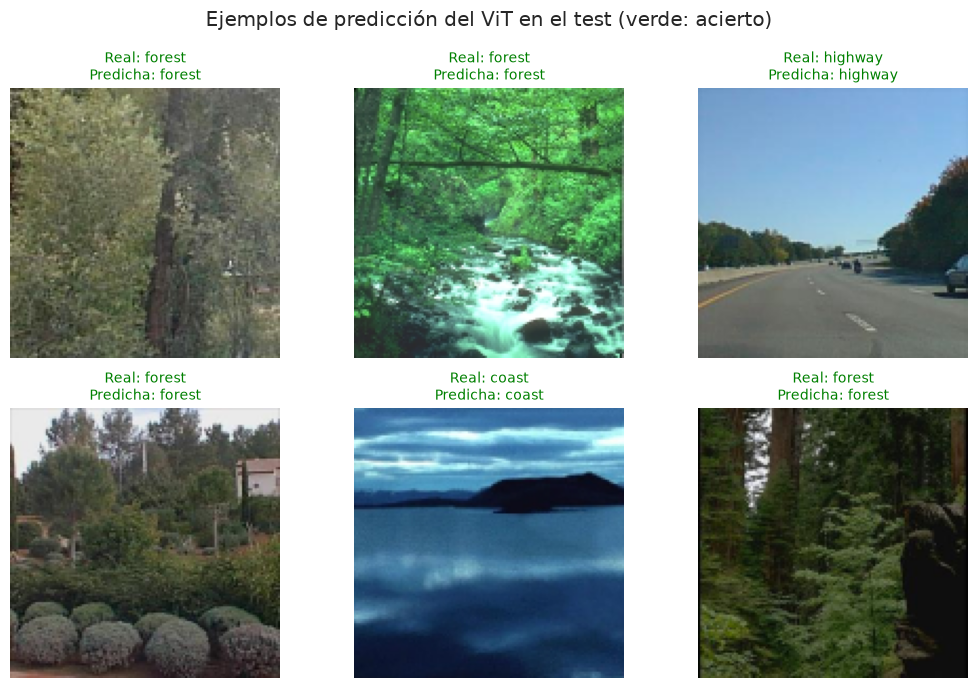

In [5]:
# Random 6-image grid from the test set with true/predicted labels.
rng = np.random.default_rng(cs.SEED)
sample_indices = rng.choice(len(X_test), size=6, replace=False)
predicted_idx, _, _ = cs.predict_keras(model, X_test)
predicted_labels = np.array(cs.CLASSES)[predicted_idx]

vit_dir = cs.result_dir("vit")
vit_dir.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(2, 3, figsize=(10.5, 7.0))
for ax, index in zip(axes.flat, sample_indices):
    true_label = y_test_labels[index]
    predicted_label = predicted_labels[index]
    ax.imshow(X_test[index].astype("uint8"))
    ax.set_title(
        f"Real: {true_label}\nPredicha: {predicted_label}",
        color="green" if true_label == predicted_label else "red",
        fontsize=10,
    )
    ax.axis("off")
fig.suptitle("Ejemplos de predicción del ViT en el test (verde: acierto)")
fig.tight_layout()
fig.savefig(vit_dir / "ejemplos_prediccion.png", dpi=150, bbox_inches="tight")
plt.show()

## Observaciones

* El ViT aplica atención **global** en todas las capas: cada uno de los 256
  parches (más el token de clase) atiende a todos los demás, sin ventanas ni
  jerarquía de escalas. Sin etapas tipo CNN, el modelo tiende a apoyarse en
  estadísticas globales de **color y textura** (el azul de mar y cielo de la
  costa, el verde denso del bosque) más que en la disposición local de los
  objetos: conviene mirar si los errores caen en imágenes donde el color
  global engaña.
* **Autopista ↔ costa** es la confusión esperada: ambas comparten horizonte
  marcado, banda central alargada (calzada o mar) y tonos gris-azulados. La
  atención global puede confundir una autopista con una costa cuando el
  asfalto y el cielo dominan el encuadre; la matriz de confusión de
  `resultados/vit/metrics.json` y la figura 2 de `reto-1.ipynb` muestran
  exactamente dónde caen esos errores.
* Entrenado **desde cero** con ~610 imágenes, lo esperable es que quede por
  debajo de la CNN mejorada v2 y lejos de la DenseNet121: sin ImageNet, la
  atención global plana no tiene pesos previos que compensen la falta de
  datos. La sección «El ViT: ¿arquitectura o preentrenamiento?» de
  `reto-1.ipynb` separa arquitectura y preentrenamiento con los números.
* Los artefactos quedan en `resultados/vit/` (`metrics.json`,
  `predictions.csv`, `history.csv`, `classification_report.txt`,
  `ejemplos_prediccion.png` y el modelo como `model.keras` +
  `model.weights.h5`); `load_vit` reconstruye la arquitectura y recarga los
  pesos para evitar los problemas de deserialización de las capas
  personalizadas.